# Relational Modelling and SQL Analytics of the QS World University Rankings

**Question.** Which of the nine QS indicators move with a university's overall position, and where do academic and employer views of a university diverge?

The data is modelled as a normalised SQLite database (`sql/schema.sql`), loaded by `src/load.py`, and every analysis below is a SQL query from `sql/queries.sql`. Python only runs the queries and draws the charts.

In [1]:
import pandas as pd
from IPython.display import Image
from src.load import build, run_named_queries
from src import plots

pd.set_option("display.max_colwidth", 60)
con = build()
q = run_named_queries(con)

## 1. The schema

Eight tables: `Country` and `University`, plus one table per indicator family, each in a one-to-one relationship with `University`. This is the entity-relationship design from the original project; the implementation changes are described in the README.

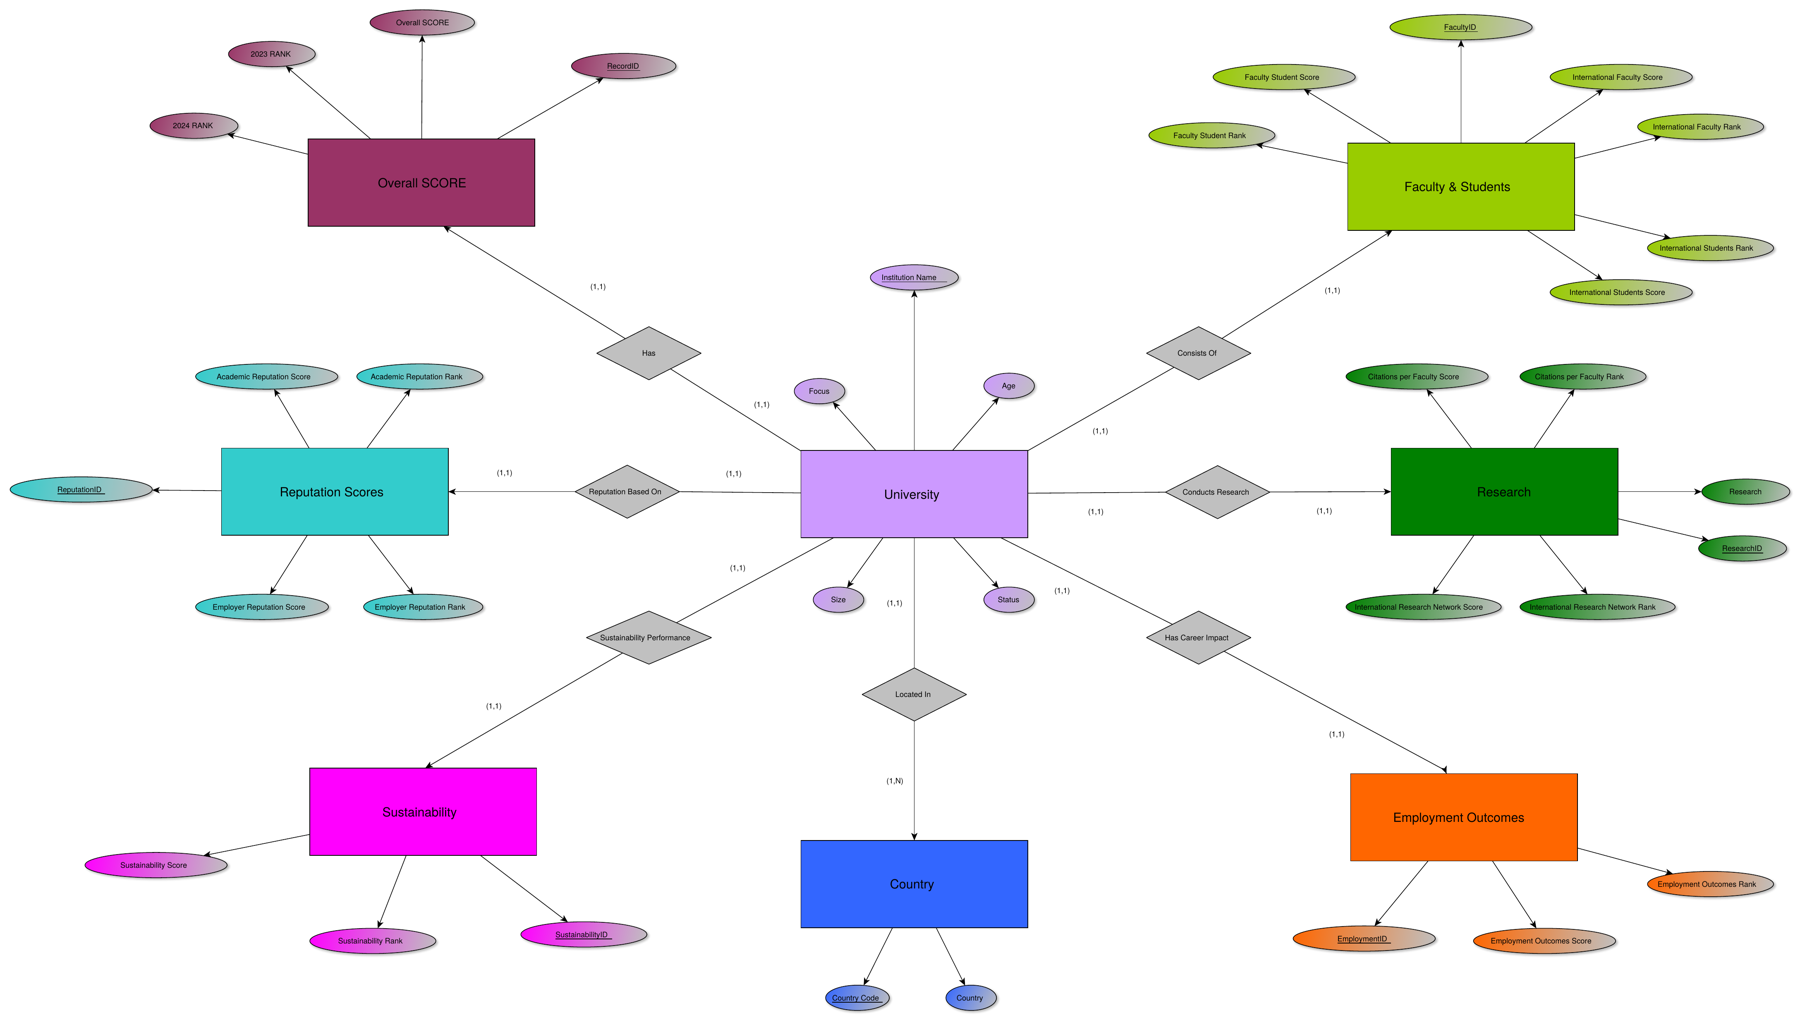

In [2]:
Image("images/er_diagram.png")

In [3]:
pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", con)

,name
0,Country
1,EmploymentOutcomes
2,FacultyStudents
3,Rankings
4,Reputation
5,Research
6,Sustainability
7,University


## 2. Coverage

QS publishes an exact rank and overall score only for the top ~600. The rest are placed in bands such as `601-610` or `1401+`. These bands are kept as text and parsed into `rank_min` / `rank_max`, and missing scores stay `NULL`.

In [4]:
q["coverage"]

,universities,with_overall_score,exact_rank,rank_band
0,1497,602,602,895


Treating missing values as zero, as the original loader did, distorts every aggregate. The average overall score falls from 40.9 to 16.4:

In [5]:
q["zero_fill_bias"]

,avg_overall_score_null_kept,avg_overall_score_zero_filled,avg_employment_null_kept,avg_employment_zero_filled
0,40.9,16.4,20.0,19.7


## 3. Which indicators move with the overall score?

Pearson correlations computed directly in SQL with a CTE and aggregate sums, over the 602 universities with a published overall score.

,indicator,n,pearson_r
0,Academic reputation,602,0.906
1,Employer reputation,602,0.746
2,Employment outcomes,601,0.688
3,Sustainability,594,0.616
4,International research network,601,0.556
5,Citations per faculty,602,0.520
6,International students,597,0.409
7,International faculty,591,0.369
8,Faculty/student ratio,601,0.319


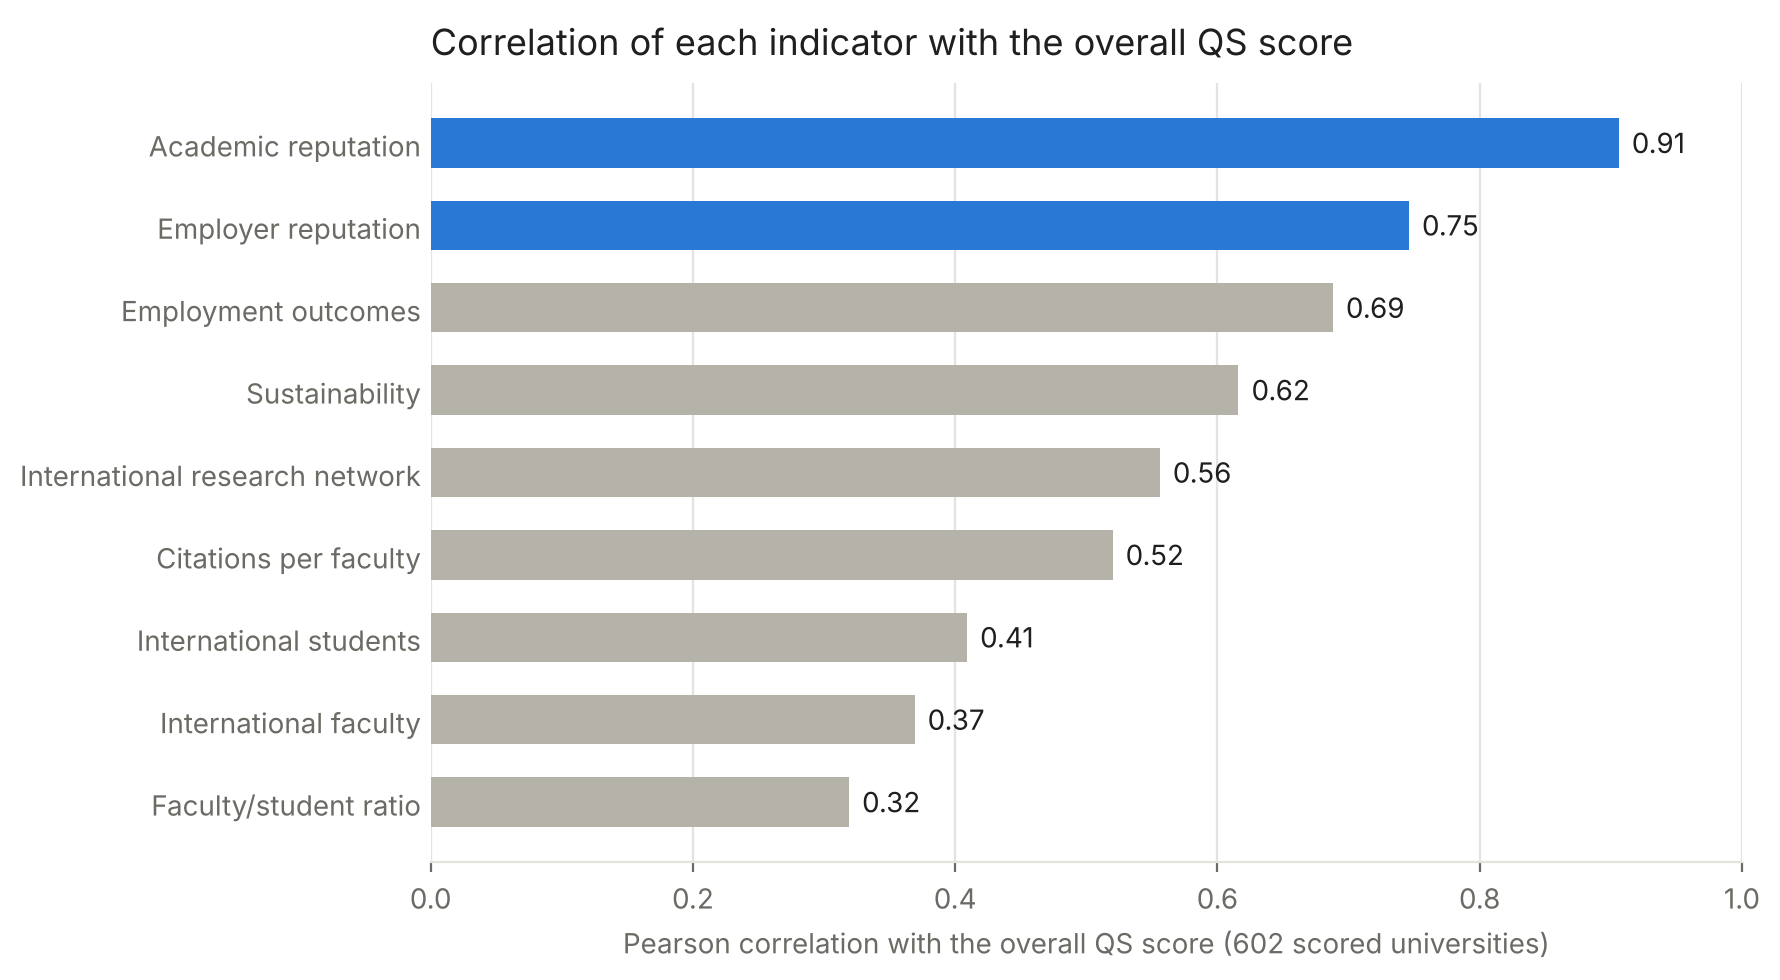

In [6]:
corr = q["indicator_correlation"]
plots.correlation_bars(corr, path="images/indicator_correlation.png")
corr

Academic reputation correlates 0.91 with the overall score. Part of this is by construction, since it is the largest single weight in the QS formula, but citations per faculty also carries a large weight and correlates only 0.52. Reputation, which comes from surveys, follows the overall ranking far more closely than measured research output does.

## 4. Where academics and employers disagree

Universities in the top 500 whose employer reputation most exceeds their academic reputation.

In [7]:
gap = q["employability_gap"]
gap

,institution_name,country_name,world_rank,academic_rep,employer_rep,gap
0,Hitotsubashi University,Japan,=481,14.4,80.6,66.2
1,Taylor's University,Malaysia,284,24.0,82.8,58.8
2,Institut Polytechnique de Paris,France,=38,44.8,99.6,54.8
3,National University of Sciences And Technology (NUST) Is...,Pakistan,367,18.9,72.7,53.8
4,Ecole des Ponts ParisTech,France,=192,8.3,57.9,49.6
5,Eindhoven University of Technology,Netherlands,=124,29.3,76.2,46.9
6,Tecnológico de Monterrey,Mexico,=184,51.3,96.8,45.5
7,RWTH Aachen University,Germany,106,49.7,93.0,43.3
8,National Taipei University of Technology,Taiwan,=431,15.0,57.7,42.7
9,Keio University,Japan,214,51.4,93.5,42.1


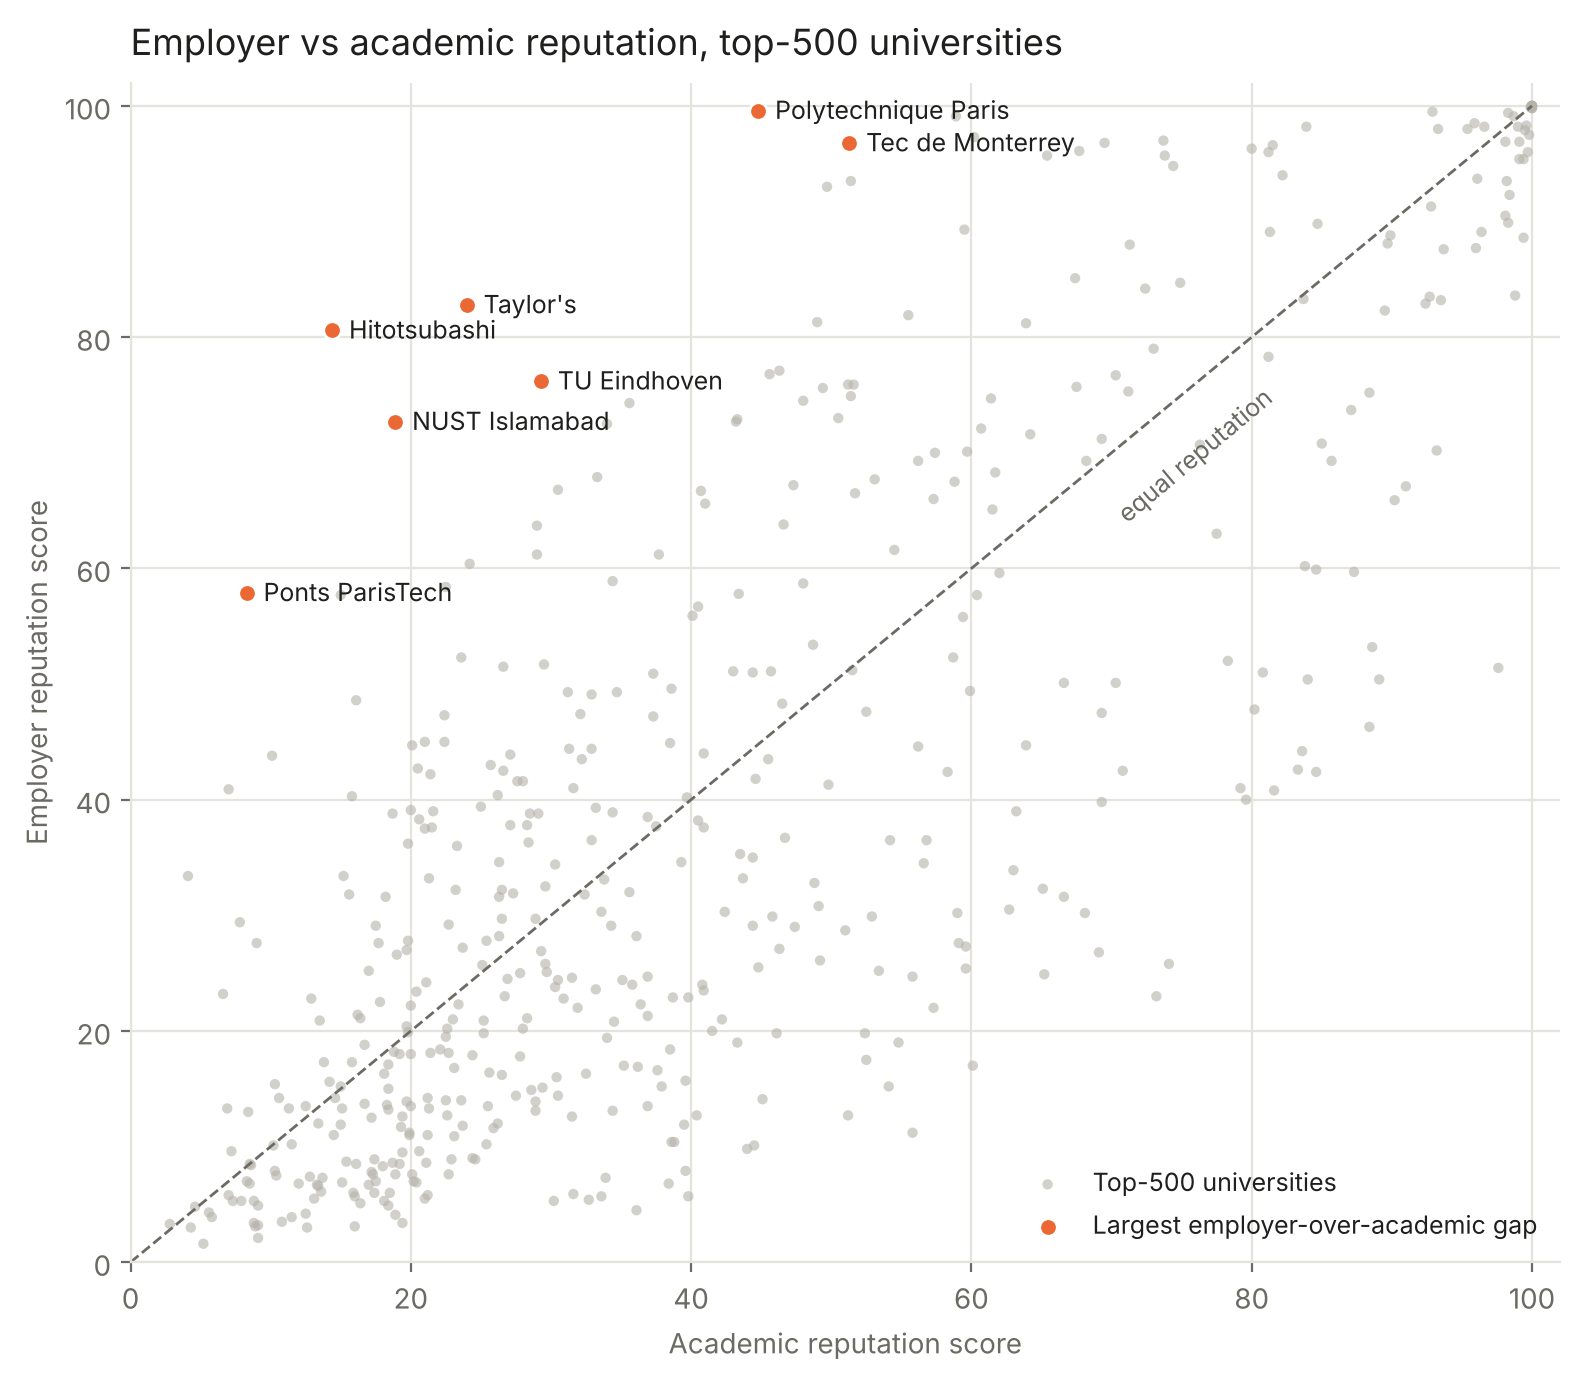

In [8]:
top500 = pd.read_sql_query('''
    SELECT u.institution_name, rp.academic_reputation_score AS academic_rep, rp.employer_reputation_score AS employer_rep
    FROM University u JOIN Rankings rk USING (university_id) JOIN Reputation rp USING (university_id)
    WHERE rk.rank_2024_max <= 500''', con)
short = {
    "Hitotsubashi University": "Hitotsubashi",
    "Taylor's University": "Taylor's",
    "Institut Polytechnique de Paris": "Polytechnique Paris",
    "National University of Sciences And Technology (NUST) Islamabad": "NUST Islamabad",
    "Ecole des Ponts ParisTech": "Ponts ParisTech",
    "Eindhoven University of Technology": "TU Eindhoven",
    "Tecnológico de Monterrey": "Tec de Monterrey",
}
top500["short_name"] = top500.institution_name.map(short)
plots.reputation_scatter(top500, list(short), path="images/reputation_gap.png");

Most universities sit close to the diagonal. The outliers are technical and business-oriented institutions, such as Hitotsubashi, Polytechnique Paris, TU Eindhoven and Tec de Monterrey: recruiters rate them far above their standing among academics.

## 5. Countries

Concentration of top-ranked universities, the best university in each of the largest systems (window function), and employment outcomes by country for systems with at least 20 ranked universities.

,country_name,top_100,top_500,ranked
0,United States,27,83,199
1,United Kingdom,17,49,90
2,Australia,9,27,38
3,China (Mainland),5,29,71
4,South Korea,5,14,43
5,Hong Kong SAR,5,6,7
6,Germany,4,30,49
7,France,4,16,35
8,Japan,4,15,50
9,Canada,3,19,31


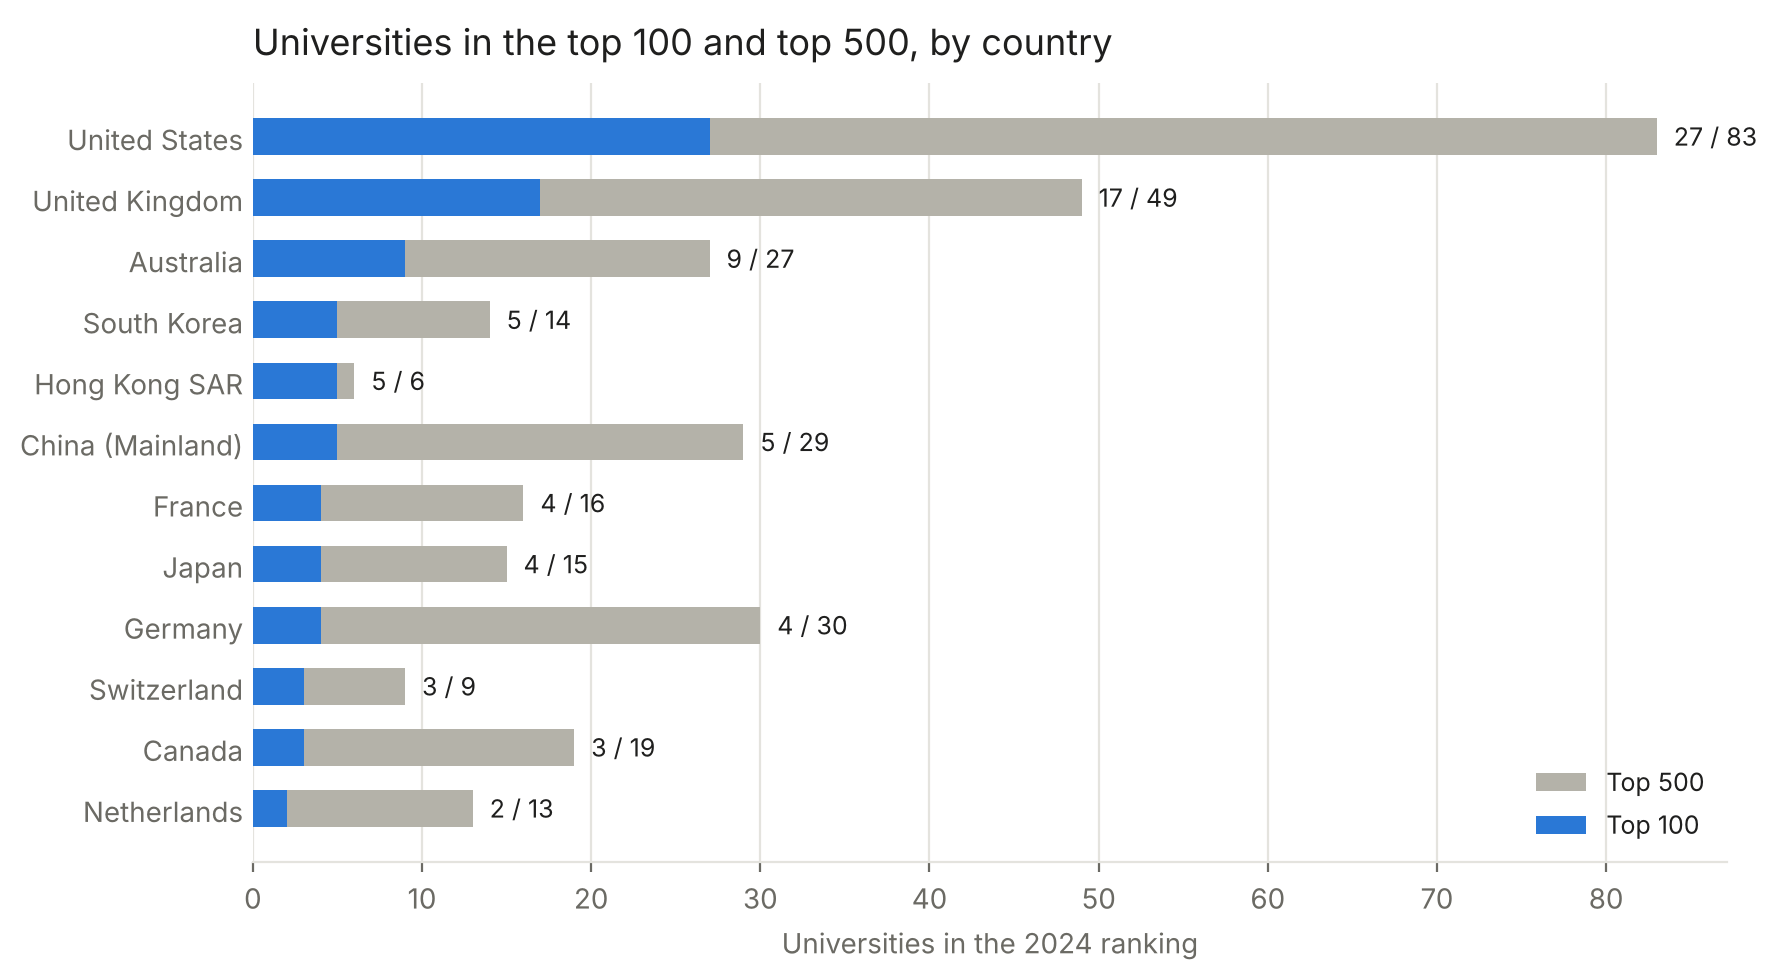

In [9]:
countries = q["country_concentration"]
plots.country_bars(countries, path="images/country_concentration.png")
countries

In [10]:
q["best_by_country"]

,country_name,best_university,world_rank,universities_in_country
0,United States,Massachusetts Institute of Technology (MIT),1,199
1,United Kingdom,University of Cambridge,2,90
2,China (Mainland),Peking University,=17,71
3,Japan,The University of Tokyo,28,50
4,Germany,Technical University of Munich,37,49
5,Russia,Lomonosov Moscow State University,=87,48
6,India,Indian Institute of Technology Bombay (IITB),=149,45
7,South Korea,Seoul National University,41,43
8,Italy,Politecnico di Milano,123,42
9,Australia,The University of Melbourne,14,38


In [11]:
q["employment_by_country"]

,country_name,universities,avg_employment_outcomes,avg_employer_reputation
0,Canada,31,32.8,27.7
1,United States,199,28.0,21.6
2,Australia,38,25.4,27.6
3,United Kingdom,90,22.0,29.6
4,Taiwan,27,20.1,23.8
5,France,33,18.7,17.2
6,Mexico,32,17.1,16.4
7,Colombia,25,17.0,25.1
8,Germany,46,16.9,24.7
9,Japan,49,16.8,27.2


## 6. Biggest moves between 2023 and 2024

In [12]:
q["biggest_movers"]

,institution_name,country_name,rank_2023,rank_2024,places_gained
0,École Normale Supérieure de Lyon,France,111,184,-73
1,Macquarie University,Australia,195,130,65
2,University of Cape Town,South Africa,237,173,64
3,Nagoya University,Japan,112,176,-64
4,University of Reading,United Kingdom,229,169,60
5,University of Calgary,Canada,242,182,60
6,Western University,Canada,172,114,58
7,Complutense University of Madrid,Spain,226,171,55
8,Hokkaido University,Japan,141,196,-55
9,RMIT University,Australia,190,140,50


## 7. Conclusions

1. **Reputation surveys dominate.** Academic reputation correlates 0.91 with the overall score; research output per faculty, with a comparable weight, correlates 0.52.
2. **Employers and academics disagree in predictable places.** The largest gaps are at technical and business-focused institutions.
3. **The top is concentrated.** The United States and the United Kingdom hold 44 of the top 100.
4. **Data handling changes the answer.** Replacing missing scores with zero, as the first version did, more than halves the average overall score and corrupts any comparison built on it.

**Limitations.** One edition of one ranking; correlations with indicators are partly mechanical because the overall score is their weighted sum; band-ranked universities have no overall score, so section 3 covers the top 602 only.